In [42]:
import pandas as pd
print(pd.__version__)

3.1.0


#  Series

In [43]:
notas = pd.Series([10, 3.2, 6.7])
notas

0    10.0
1     3.2
2     6.7
dtype: float64

In [44]:
print(notas.index)

RangeIndex(start=0, stop=3, step=1)


In [45]:
print(notas.to_numpy())

[10.   3.2  6.7]


In [46]:
notas = pd.Series([10, 3.2, 6], index=["prova 1", "prova 2", "prova 3"])
print(notas)
print('-----')
print(notas["prova 1"])
print('-----')
print(notas.mean())
print('-----')
print(notas[notas > 4])
print('-----')
print(notas.describe())

prova 1    10.0
prova 2     3.2
prova 3     6.0
dtype: float64
-----
10.0
-----
6.3999999999999995
-----
prova 1    10.0
prova 3     6.0
dtype: float64
-----
count     3.000000
mean      6.400000
std       3.417601
min       3.200000
25%       4.600000
50%       6.000000
75%       8.000000
max      10.000000
dtype: float64


In [47]:
a = pd.Series({"Ohio": 3500, "Texas": 71000, "Oregon": 16000})
print(a)
print()
b = pd.Series({"Texas": 1000, "Oregon": 2000, "Utah": 500})
print(b)
print()
print(a+b)
print()
a.add(b, fill_value=0)


Ohio       3500
Texas     71000
Oregon    16000
dtype: int64

Texas     1000
Oregon    2000
Utah       500
dtype: int64

Ohio          NaN
Oregon    18000.0
Texas     72000.0
Utah          NaN
dtype: float64



Ohio       3500.0
Oregon    18000.0
Texas     72000.0
Utah        500.0
dtype: float64

# Series a partir de um dicionário e valores ausentes

In [48]:
populacao = pd.Series({
    "Ohio": None,
    "Texas": 7100,
    "Oregon": 1600,
    "Utah": 500,
})
print(populacao)
print()
print(populacao[populacao.isna()])
print()
print(populacao[populacao.notna()])
print()
populacao.name = "População"
print(populacao)
print()
populacao.index.name = "Estado"
print(populacao)

Ohio         NaN
Texas     7100.0
Oregon    1600.0
Utah       500.0
dtype: float64

Ohio   NaN
dtype: float64

Texas     7100.0
Oregon    1600.0
Utah       500.0
dtype: float64

Ohio         NaN
Texas     7100.0
Oregon    1600.0
Utah       500.0
Name: População, dtype: float64

Estado
Ohio         NaN
Texas     7100.0
Oregon    1600.0
Utah       500.0
Name: População, dtype: float64


# DataFrames

In [49]:
dados = {
    "estado": [f'estado {x}' for x in range(1, 5)],
    'ano': [2000, 2001, 2002, 2005],
    'populacao': [1.5, 1.6, 1.7, 1.8]
}
df = pd.DataFrame(dados)
df

,estado,ano,populacao
0,estado 1,2000,1.5
1,estado 2,2001,1.6
2,estado 3,2002,1.7
3,estado 4,2005,1.8


In [50]:
print(df.shape)
print()
print(df.columns)
print()
print(df.head(3))
print()
print(df['estado'])
print()
print(df[['estado', 'populacao']])

(4, 3)

Index(['estado', 'ano', 'populacao'], dtype='str')

     estado   ano  populacao
0  estado 1  2000        1.5
1  estado 2  2001        1.6
2  estado 3  2002        1.7

0    estado 1
1    estado 2
2    estado 3
3    estado 4
Name: estado, dtype: str

     estado  populacao
0  estado 1        1.5
1  estado 2        1.6
2  estado 3        1.7
3  estado 4        1.8


In [51]:
df["populacao_mil"] = df["populacao"] * 1000
df


,estado,ano,populacao,populacao_mil
0,estado 1,2000,1.5,1500.0
1,estado 2,2001,1.6,1600.0
2,estado 3,2002,1.7,1700.0
3,estado 4,2005,1.8,1800.0


In [52]:
sem_estado = df.drop(columns=["estado"])
sem_estado

,ano,populacao,populacao_mil
0,2000,1.5,1500.0
1,2001,1.6,1600.0
2,2002,1.7,1700.0
3,2005,1.8,1800.0


In [53]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   estado         4 non-null      str    
 1   ano            4 non-null      int64  
 2   populacao      4 non-null      float64
 3   populacao_mil  4 non-null      float64
dtypes: float64(2), int64(1), str(1)
memory usage: 260.0 bytes


In [54]:
df.describe()

,ano,populacao,populacao_mil
count,4.000000,4.000000,4.000000
mean,2002.000000,1.650000,1650.000000
std,2.160247,0.129099,129.099445
min,2000.000000,1.500000,1500.000000
25%,2000.750000,1.575000,1575.000000
50%,2001.500000,1.650000,1650.000000
75%,2002.750000,1.725000,1725.000000
max,2005.000000,1.800000,1800.000000


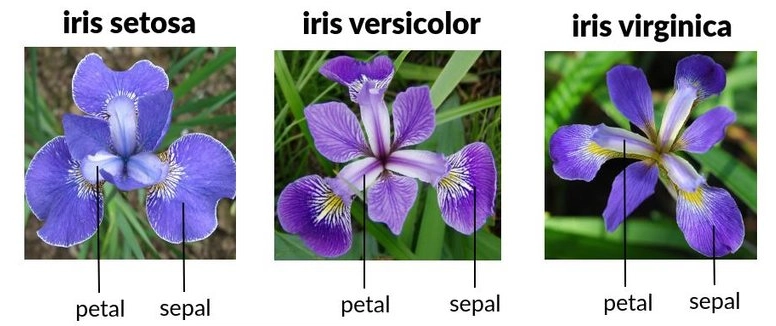

In [55]:
url = 'http://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data'

colunas = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'class']

df = pd.read_csv(url, names=colunas)

print(df.head())

print(df.tail())

print(df.describe())

print(df.info())

   sepal_length  sepal_width  petal_length  petal_width        class
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa
     sepal_length  sepal_width  petal_length  petal_width           class
145           6.7          3.0           5.2          2.3  Iris-virginica
146           6.3          2.5           5.0          1.9  Iris-virginica
147           6.5          3.0           5.2          2.0  Iris-virginica
148           6.2          3.4           5.4          2.3  Iris-virginica
149           5.9          3.0           5.1          1.8  Iris-virginica
       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333   

In [56]:
df["class"].value_counts()

class
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

In [57]:
df.groupby("class").mean().round(2)

,sepal_length,sepal_width,petal_length,petal_width
class,,,,
Iris-setosa,5.01,3.42,1.46,0.24
Iris-versicolor,5.94,2.77,4.26,1.33
Iris-virginica,6.59,2.97,5.55,2.03


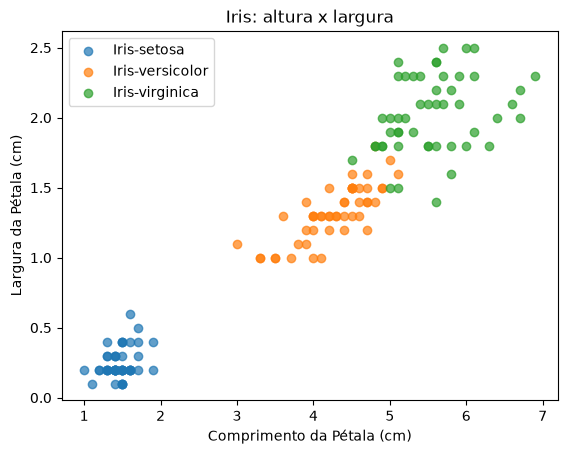

In [62]:
import matplotlib.pyplot as plt

for especie, grupo in df.groupby('class'):
    plt.scatter(grupo['petal_length'], grupo['petal_width'], label=especie, alpha=0.7 )
plt.xlabel("Comprimento da Pétala (cm)")
plt.ylabel("Largura da Pétala (cm)")
plt.title("Iris: altura x largura")
plt.legend()
plt.show()